In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from numpy.f2py.auxfuncs import throw_error

In [ ]:
#Parent class for neurons
class Neuron:
    def __init__(self):
        return
    def forward_pass(self,x):
        return
    def backward_pass(self, derivative):
        return
    def update(self, derivative):
        return

In [ ]:
#Class for individual neuron, will expand into a layer
class Linear(Neuron):
    def __init__(self,learning_rate = 0.001, weight=np.inf, bias=np.inf):
        super().__init__()
        self.x = None
        self.learning_rate = learning_rate
        self.bias = bias if bias != np.inf else np.random.uniform(-1,1,size=[1])[0]
        self.weight = weight if weight != np.inf else np.random.uniform(-1,1,size=[1])[0]
    def forward_pass(self,x):
        self.x = x
        return self.weight*x + self.bias
    def backward_pass(self, derivative):
        return derivative * self.weight
    def update(self, derivative):
        self.weight -= self.learning_rate*np.average(self.x * derivative)
        self.bias -= np.average(self.learning_rate * derivative)
        self.x = np.array([])

In [ ]:
#Class for individual neuron (Relu)
class Relu(Neuron):
    def __init__(self):
        super().__init__()
        self.x = None
        self.gradient = None

    def forward_pass(self,x):
        self.gradient = np.where(x > 0, 1, 0)
        self.x = x
        return self.x * self.gradient
    def backward_pass(self, derivative):
        return derivative * self.gradient

In [ ]:
#Class for leaky ReLU
class LeakyRelu(Neuron):
    def __init__(self, alpha=0.01):
        super().__init__()
        self.x = None
        self.gradient = None
        self.alpha = alpha
    def forward_pass(self,x):
        self.gradient = np.where(x > 0, 1, self.alpha)
        self.x = x
        return self.x * self.gradient
    def backward_pass(self, derivative):
        return derivative * self.gradient


In [405]:
#Model class for multi-layer perceptron
class Model:
    def __init__(self, layers):
        self.layers = layers

    def forward_pass(self,x):
        input = x
        for i in self.layers:
            input = i.forward_pass(input)
        return input

    def backward_pass(self, derivative):
        gradient = derivative
        for i in reversed(self.layers):
            temp2 = i.backward_pass(gradient)
            i.update(gradient)
            gradient = temp2

    def train(self,x,y,iterations=10000,cutoff = 0.001):
        cost_history = []
        for i in range(iterations):
            prediction = self.forward_pass(x)
            loss = prediction - y
            cost_history.append(np.average(loss**2)/2)
            self.backward_pass(loss)
            if len(cost_history) < 2:
                continue
            if abs((cost_history[-1]-cost_history[-2])/cost_history[-1]) < cutoff:
                break
        return cost_history

    def train_advanced(self, x, y, epoch, batch_size, iterations=10000, cutoff = 0.001):
        cost_history = []
        counter = 0
        for i in range(epoch):
            batches = self.create_batches(x,y,batch_size)
            for batch in batches:
                batch_x = batch[0]
                batch_y = batch[1]
                prediction = self.forward_pass(batch_x)
                loss = prediction - batch_y
                cost_history.append(np.average(loss**2)/2)
                self.backward_pass(loss)
                if len(cost_history) < 2:
                    continue
                if abs((cost_history[-1]-cost_history[-2])/cost_history[-1]) < cutoff:
                    return cost_history
                if counter == iterations:
                    break
                counter += 1
        return cost_history

    def create_batches(self,x,y,batch_size):
        if batch_size > len(x):
            raise Exception("Batch size cannot be larger than the dataset size.")
        indexes = np.arange(len(x))
        np.random.shuffle(indexes)
        x_shuffled = x[indexes]
        y_shuffled = y[indexes]
        batches = len(x)//batch_size
        output = np.empty((batches,2,batch_size))
        for i in range(batches):
            output[i,0] = x_shuffled[i*batch_size:(i+1)*batch_size]
            output[i,1] = y_shuffled[i*batch_size:(i+1)*batch_size]
        return output

In [391]:
#Testing create_batches function
model = Model(np.empty(0))
batches = model.create_batches(np.array([1,2,3,4,5,6,7,8,9,10]), np.array([1,2,3,4,5,6,7,8,9,10]), 4)
print(batches)

[[[ 6.  8.  4.  9.]
  [ 6.  8.  4.  9.]]

 [[ 1. 10.  2.  5.]
  [ 1. 10.  2.  5.]]]


In [ ]:
#Creating layers
learning_rate = 0.001
input = Linear(learning_rate)
output = Linear(learning_rate)
model = Model([input,output])
print(f"input weight: {input.weight}, input bias: {input.bias},\noutput weight: {output.weight}, output bias: {output.bias}")

In [ ]:
#Horners method for polynomial evaluation
def polynomial(x, coefficients):
    y = 0
    for c in coefficients:
        y = y*x + c
    return y

In [ ]:
#Creating inputs:
scale = 1
size = 100
deviation = 0.01
x = np.random.uniform(-scale,scale,size=[size])
x.sort()
y = polynomial(x, [3, 2, -5]) + np.random.normal(0,scale*deviation,size=[size])

plt.plot(x,y,'o',label="Training data")
plt.plot(np.array([np.min(x),np.max(x)]),np.array([np.min(y),np.max(y)]),label="Fit")
plt.legend()
plt.show()

In [ ]:
#Simulating forwards pass:

#Creating layers
learning_rate = 0.1
init = 2
input = Linear(learning_rate,np.random.uniform(-init,init,size=[1])[0],np.random.uniform(-1,1,size=[1])[0])
activation = LeakyRelu()
output = Linear(learning_rate,np.random.uniform(-init,init,size=[1])[0],np.random.uniform(-1,1,size=[1])[0])
model = [Linear(learning_rate),LeakyRelu(),Linear(learning_rate),LeakyRelu(),Linear(learning_rate)]

temp = x
for i in model:
    temp = i.forward_pass(temp)

plt.plot(x,y,'o',label="Training data")
plt.plot(x,temp,label="prediction")
plt.plot(x,y-temp,'o',label="Loss",color="red")
plt.legend()
plt.show()

cost_history = []
for i in range(100):
    temp = temp-y
    cost_history.append(np.average(temp**2)/2)
    for j in reversed(model):
        temp2 = j.backward_pass(temp)
        j.update(temp)
        temp = temp2

    temp = x
    for j in model:
        temp = j.forward_pass(temp)

plt.plot(cost_history,'o',label="Cost")
plt.legend()
plt.show()

plt.plot(x,y,'o',label="Training data")
plt.plot(x,y-temp,'o',label="Loss",color="red")
plt.plot(x,temp,label="prediction")
plt.legend()
plt.show()

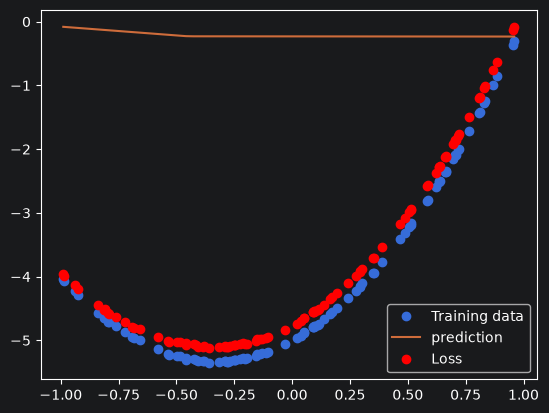

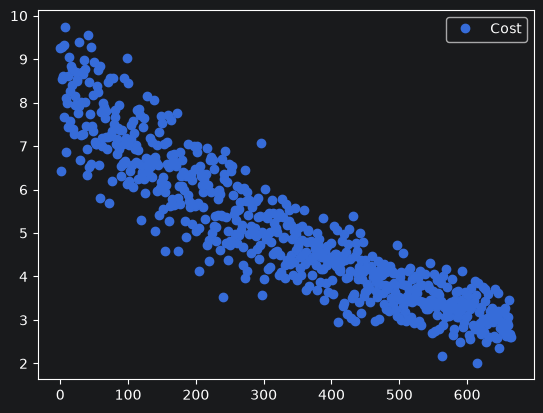

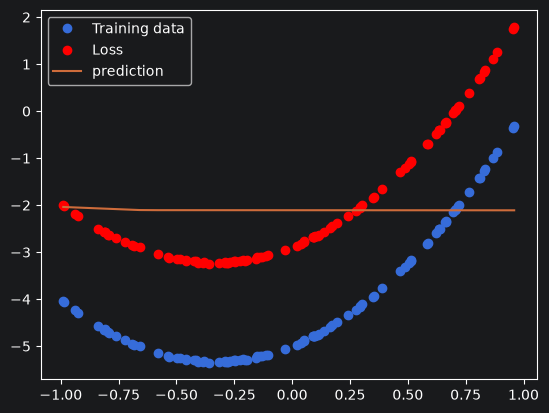

In [408]:
#Utilizing model class
learning_rate = 0.001
model = Model([Linear(learning_rate),LeakyRelu(0.01),Linear(learning_rate)])

prediction = model.forward_pass(x)

plt.plot(x,y,'o',label="Training data")
plt.plot(x,prediction,label="prediction")
plt.plot(x,y-prediction,'o',label="Loss",color="red")
plt.legend()
plt.show()

cost_history = model.train_advanced(x,y,1000,20,iterations=10000,cutoff=0.001)
prediction = model.forward_pass(x)

plt.plot(cost_history,'o',label="Cost")
plt.legend()
plt.show()

plt.plot(x,y,'o',label="Training data")
plt.plot(x,y-prediction,'o',label="Loss",color="red")
plt.plot(x,prediction,label="prediction")
plt.legend()
plt.show()